In [20]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import calendar

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from poreallas.utils import analysis as analysis_utils

In [8]:
era5_6hr_raw = xr.open_zarr("./data/v2611/v20261108_era5_6hrly.zarr")
era5_1hr_raw = xr.open_zarr("./data/v2611/v20261110_era5_hrly.zarr")

In [25]:
diff = era5_6hr_raw['tas']-era5_1hr_raw['tas']


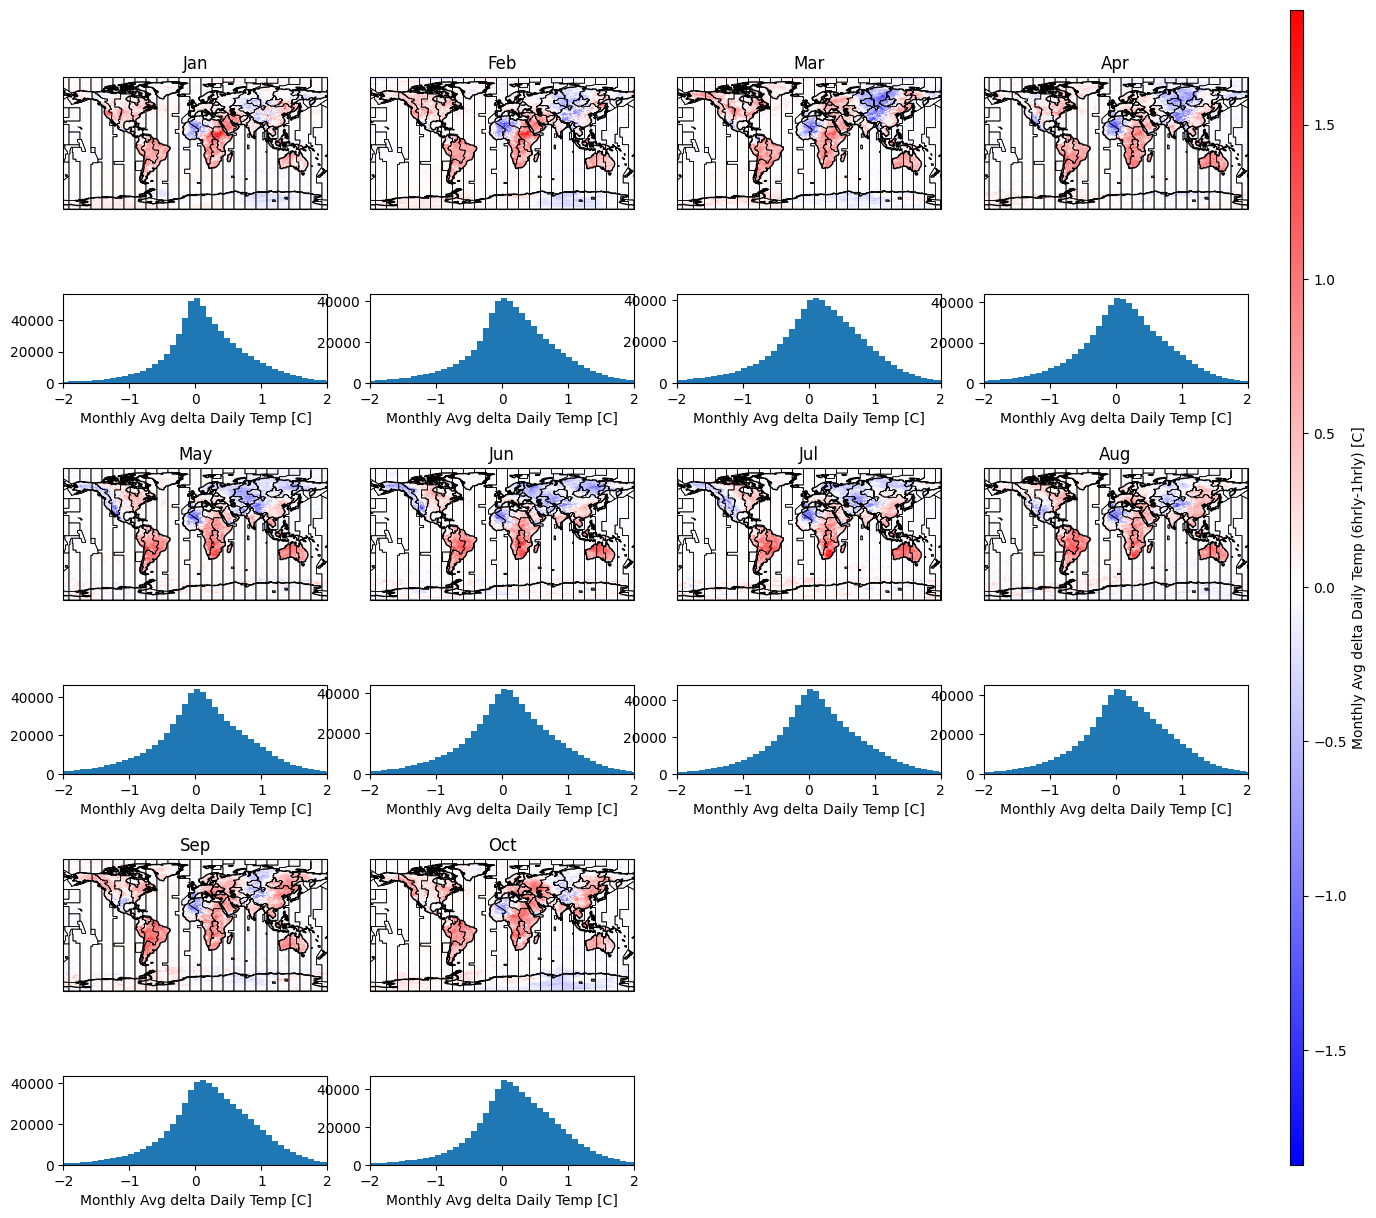

In [29]:
land = analysis_utils.land_only(diff)
monthly = diff.groupby('time.month').mean('time')

tz = cfeature.NaturalEarthFeature('cultural', 'time_zones', '10m',
                                  facecolor='none', edgecolor='black')

ncols, nrows = 4, 3
fig = plt.figure(figsize=(16, 15))
gs = fig.add_gridspec(nrows * 2, ncols + 1, height_ratios=[3, 1] * nrows,
                      width_ratios=[1] * ncols + [0.05], hspace=0.1)

vlim = float(abs(monthly).max())

bins = np.linspace(float(land.min()), float(land.max()), 200)
map_axes = []

for i, month in enumerate(monthly.month.values):
    r, c = divmod(i, ncols)

    ax_map = fig.add_subplot(gs[2 * r, c], projection=ccrs.PlateCarree())
    im = monthly.sel(month=month).plot(ax=ax_map, transform=ccrs.PlateCarree(),
                                    cmap='bwr', vmin=-vlim, vmax=vlim,
                                    add_colorbar=False)
    ax_map.add_feature(tz, linewidth=0.5)
    ax_map.coastlines()
    ax_map.set_title(calendar.month_abbr[month])
    map_axes.append(ax_map)

    ax_hist = fig.add_subplot(gs[2 * r + 1, c])
    vals = land.sel(time=land['time.month'] == month).values.ravel()
    ax_hist.hist(vals[~np.isnan(vals)], bins=bins)
    ax_hist.set_xlim([-2, 2])
    ax_hist.set_xlabel("Monthly Avg delta Daily Temp [C]")

fig.colorbar(im, cax=fig.add_subplot(gs[:, -1]), label='Monthly Avg delta Daily Temp (6hrly-1hrly) [C]')

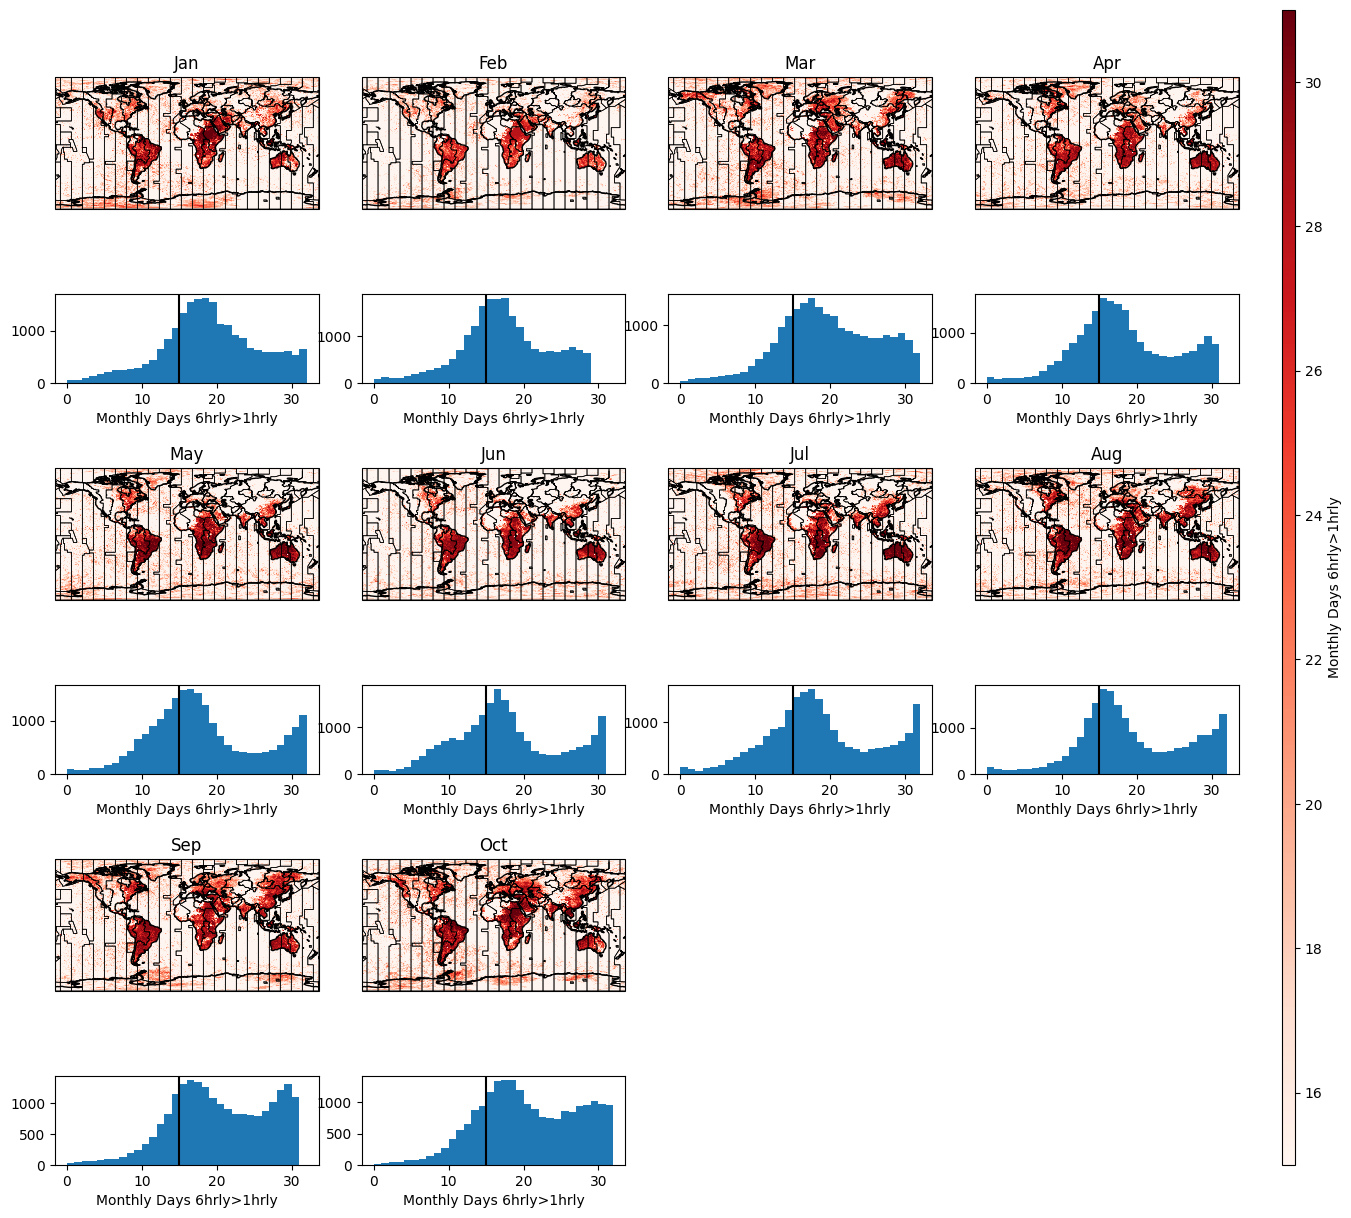

In [32]:
exceed = (diff > 0).where(diff.notnull())
counts = exceed.resample(time='1MS').sum(min_count=1)
monthly = counts.groupby('time.month').mean('time')
land = analysis_utils.land_only(monthly)

tz = cfeature.NaturalEarthFeature('cultural', 'time_zones', '10m',
                                  facecolor='none', edgecolor='black')

ncols, nrows = 4, 3
fig = plt.figure(figsize=(16, 15))
gs = fig.add_gridspec(nrows * 2, ncols + 1, height_ratios=[3, 1] * nrows,
                      width_ratios=[1] * ncols + [0.05], hspace=0.1)

vlim = float(abs(monthly).max())

bins = np.arange(0, 33)
map_axes = []

for i, month in enumerate(monthly.month.values):
    r, c = divmod(i, ncols)

    ax_map = fig.add_subplot(gs[2 * r, c], projection=ccrs.PlateCarree())
    im = monthly.sel(month=month).plot(ax=ax_map, transform=ccrs.PlateCarree(),
                                   cmap='Reds', vmin=15, vmax=31,
                                   add_colorbar=False)
    ax_map.add_feature(tz, linewidth=0.5)
    ax_map.coastlines()
    ax_map.set_title(calendar.month_abbr[month])
    map_axes.append(ax_map)

    ax_hist = fig.add_subplot(gs[2 * r + 1, c])
    vals = land.sel(month=month).values.ravel()
    ax_hist.hist(vals[~np.isnan(vals)], bins=bins)
    ax_hist.axvline(15, color = 'black')
    ax_hist.set_xlabel('Monthly Days 6hrly>1hrly')

fig.colorbar(im, cax=fig.add_subplot(gs[:, -1]), label='Monthly Days 6hrly>1hrly')